In [4]:
import pandas as pd
import mysql.connector
import os

# List of CSV files and their corresponding table names
csv_files = [
    ('customers.csv', 'customers'),
    ('orders.csv', 'orders'),
    ('sallers.csv', 'sallers'),
    ('products.csv', 'products'),
    ('delivery.csv', 'delivery'),
    ('payments.csv', 'payments'),
    ('order_items.csv','order_items')  # Added payments.csv for specific handling
]

# Connect to the MySQL database
conn = mysql.connector.connect(
    host='localhost',
    user='root',
    password='1234',
    database='ecommerce'
)
cursor = conn.cursor()

# Folder containing the CSV files
folder_path = 'C:/Users/NEWUS/Desktop/ergf/ecommerce'

def get_sql_type(dtype):
    if pd.api.types.is_integer_dtype(dtype):
        return 'INT'
    elif pd.api.types.is_float_dtype(dtype):
        return 'FLOAT'
    elif pd.api.types.is_bool_dtype(dtype):
        return 'BOOLEAN'
    elif pd.api.types.is_datetime64_any_dtype(dtype):
        return 'DATETIME'
    else:
        return 'TEXT'

for csv_file, table_name in csv_files:
    file_path = os.path.join(folder_path, csv_file)
    
    # Read the CSV file into a pandas DataFrame
    df = pd.read_csv(file_path)
    
    # Replace NaN with None to handle SQL NULL
    df = df.where(pd.notnull(df), None)
    
    # Debugging: Check for NaN values
    print(f"Processing {csv_file}")
    print(f"NaN values before replacement:\n{df.isnull().sum()}\n")

    # Clean column names
    df.columns = [col.replace(' ', '_').replace('-', '_').replace('.', '_') for col in df.columns]

    # Generate the CREATE TABLE statement with appropriate data types
    columns = ', '.join([f'`{col}` {get_sql_type(df[col].dtype)}' for col in df.columns])
    create_table_query = f'CREATE TABLE IF NOT EXISTS `{table_name}` ({columns})'
    cursor.execute(create_table_query)

    # Insert DataFrame data into the MySQL table
    for _, row in df.iterrows():
        # Convert row to tuple and handle NaN/None explicitly
        values = tuple(None if pd.isna(x) else x for x in row)
        sql = f"INSERT INTO `{table_name}` ({', '.join(['`' + col + '`' for col in df.columns])}) VALUES ({', '.join(['%s'] * len(row))})"
        cursor.execute(sql, values)

    # Commit the transaction for the current CSV file
    conn.commit()

# Close the connection
conn.close()

Processing customers.csv
NaN values before replacement:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Processing orders.csv
NaN values before replacement:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64



FileNotFoundError: [Errno 2] No such file or directory: 'C:/Users/NEWUS/Desktop/ergf/ecommerce\\sallers.csv'

In [76]:

import pandas as pd
import mysql.connector
import os
import sys
from decimal import Decimal, InvalidOperation

# ==========================================
# 1. CONFIGURATION
# ==========================================

folder_path = r"C:/Users/NEWUS/Desktop/ergf/ecommerce"

csv_files = [
    ("customers.csv", "customers"),
    ("orders.csv", "orders"),
    ("sellers.csv", "sellers"),
    ("delivery.csv", "delivery"),
    ("payments.csv", "payments"),
    ("order_items.csv", "order_items"),
    ("geolocation.csv","geolocation"),
    ("products.csv","products")
]

db_config = {
    "host": "localhost",
    "user": "root",
    "password": "1234",
    "database": "ecommerce"
}

# ==========================================
# 2. CONNECT TO MYSQL
# ==========================================

conn = None
cursor = None

try:
    conn = mysql.connector.connect(**db_config)
    cursor = conn.cursor()

    print("MySQL connected successfully!")

    # ==========================================
    # 3. SQL DATA TYPE DETECTION
    # ==========================================

    def get_sql_type(series):
        if pd.api.types.is_bool_dtype(series.dtype):
            return "BOOLEAN"

        if pd.api.types.is_integer_dtype(series.dtype):
            return "BIGINT"

        if pd.api.types.is_float_dtype(series.dtype):
            return "DOUBLE"

        # Use TEXT for strings and object columns.
        # Refine date and decimal columns in production.
        return "TEXT"

    # ==========================================
    # 4. PROCESS CSV FILES
    # ==========================================

    for csv_file, table_name in csv_files:

        file_path = os.path.join(folder_path, csv_file)

        print("\n" + "=" * 50)
        print("Processing:", csv_file)

        # Check whether file exists
        if not os.path.isfile(file_path):
            print("FILE NOT FOUND:", file_path)
            continue

        # Read CSV
        try:
            df = pd.read_csv(file_path)
        except Exception as e:
            print("CSV reading error:", e)
            continue

        if df.empty:
            print("CSV is empty. Skipping:", csv_file)
            continue

        # ==========================================
        # 5. CLEAN COLUMN NAMES
        # ==========================================

        df.columns = [
            str(col).strip()
            .replace(" ", "_")
            .replace("-", "_")
            .replace(".", "_")
            for col in df.columns
        ]

        if not all(df.columns):
            print("Empty column name found. Skipping:", csv_file)
            continue

        if not df.columns.is_unique:
            print("Duplicate column names after cleaning. Skipping:", csv_file)
            continue

        # ==========================================
        # 6. CREATE MYSQL TABLE
        # ==========================================

        column_definitions = []

        for col in df.columns:
            sql_type = get_sql_type(df[col])
            column_definitions.append(
                f"`{col}` {sql_type} NULL"
            )

        columns_sql = ", ".join(column_definitions)

        create_table_sql = (
            f"CREATE TABLE IF NOT EXISTS `{table_name}` "
            f"({columns_sql})"
        )

        try:
            cursor.execute(create_table_sql)
        except mysql.connector.Error as e:
            print("Table creation error:", e)
            continue

        # ==========================================
        # 7. PREPARE INSERT QUERY
        # ==========================================

        column_names = ", ".join(
            f"`{col}`" for col in df.columns
        )

        placeholders = ", ".join(
            ["%s"] * len(df.columns)
        )

        insert_sql = (
            f"INSERT INTO `{table_name}` "
            f"({column_names}) VALUES ({placeholders})"
        )

        # ==========================================
        # 8. HANDLE NaN AND NaT VALUES
        # ==========================================

        data = []

        for row in df.itertuples(index=False, name=None):
            cleaned_row = []

            for value in row:

                if pd.isna(value):
                    cleaned_row.append(None)

                elif hasattr(value, "to_pydatetime"):
                    cleaned_row.append(value.to_pydatetime())

                elif hasattr(value, "item"):
                    cleaned_row.append(value.item())

                else:
                    cleaned_row.append(value)

            data.append(tuple(cleaned_row))

        # ==========================================
        # 9. INSERT DATA IN BATCHES
        # ==========================================

        batch_size = 1000
        inserted = 0

        try:
            for start in range(0, len(data), batch_size):
                batch = data[start:start + batch_size]

                cursor.executemany(insert_sql, batch)
                conn.commit()

                inserted += len(batch)

            print("Table:", table_name)
            print("Rows in CSV:", len(df))
            print("Rows inserted:", inserted)
            print("Import successful!")

        except mysql.connector.Error as e:
            conn.rollback()
            print("Insertion error:", e)
            print("The current batch was rolled back.")
            print("Earlier committed batches may remain in the table.")

    print("\nAll CSV files have been processed.")

except mysql.connector.Error as e:
    print("MySQL connection/database error:", e)

except Exception as e:
    print("Unexpected error:", e)

finally:
    if cursor is not None:
        cursor.close()

    if conn is not None and conn.is_connected():
        conn.close()

    print("MySQL connection closed.")


MySQL connected successfully!

Processing: customers.csv
Table: customers
Rows in CSV: 99441
Rows inserted: 99441
Import successful!

Processing: orders.csv
Table: orders
Rows in CSV: 99441
Rows inserted: 99441
Import successful!

Processing: sellers.csv
Table: sellers
Rows in CSV: 3095
Rows inserted: 3095
Import successful!

Processing: delivery.csv
FILE NOT FOUND: C:/Users/NEWUS/Desktop/ergf/ecommerce\delivery.csv

Processing: payments.csv
Table: payments
Rows in CSV: 103886
Rows inserted: 103886
Import successful!

Processing: order_items.csv
Table: order_items
Rows in CSV: 112650
Rows inserted: 112650
Import successful!

Processing: geolocation.csv
Table: geolocation
Rows in CSV: 1000163
Rows inserted: 1000163
Import successful!

Processing: products.csv
Table: products
Rows in CSV: 32951
Rows inserted: 32951
Import successful!

All CSV files have been processed.
MySQL connection closed.


In [2]:
import pandas as pd
import seaborn as sns
import mysql.connector
db=mysql.connector.connect(host="localhost",
                           user="root",
                           password="1234",
                           database="ecommerce")

cur= db.cursor()



List all unique cities where customers are located.

In [7]:
query=""" select distinct(customer_city) from customers"""
cur.execute(query)
data=cur.fetchall()
df= pd.DataFrame(data,columns=["Customer_city"])
df


,Customer_city
0,franca
1,sao bernardo do campo
2,sao paulo
3,mogi das cruzes
4,campinas
...,...
4114,siriji
4115,natividade da serra
4116,monte bonito
4117,sao rafael


 Count the number of orders placed in 2017.

In [8]:
query=""" select count(order_id)from orders where year(order_purchase_timestamp)=2017"""
cur.execute(query)
data=cur.fetchall()
"total orders placed in 2017 are",data[0][0]
# df= pd.DataFrame(data,columns=["Customer_city"])
# df


('total orders placed in 2017 are', 270606)

Find the total sales per category.

In [27]:
query=""" select products.product_category category,round(sum(payments.payment_value),2) sales
from products join order_items
on products.product_id = order_items.product_id
join payments
on payments.order_id = order_items.order_id
group by category """
cur.execute(query)
data=cur.fetchall()
data
df= pd.DataFrame(data,columns=["category","sales"]).head(5)
df

,category,sales
0,perfumery,25336933.0
1,Furniture Decoration,71508819.5
2,telephony,24344102.5
3,bed table bath,85627683.5
4,automotive,42614716.5


Calculate the percentage of orders that were paid in installments.

In [12]:
query="""select (sum(case when payment_installments>= 1 then 1
else 0 end))/count(*)*100 from payments """
cur.execute(query)
data=cur.fetchall()
"the percentage of orders that were paid in installments",data


('the percentage of orders that were paid in installments',
 [(Decimal('99.9981'),)])

 Count the number of customers from each state. 

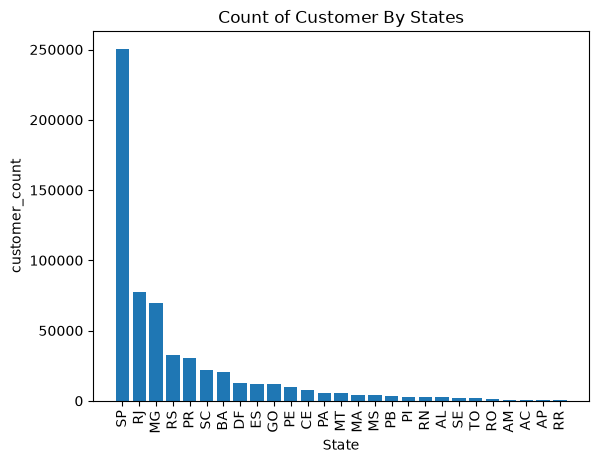

In [52]:
import matplotlib.pyplot as plt
query="""select customer_state,count(customer_id) 
from customers group by customer_state """
cur.execute(query)
data=cur.fetchall()
df=pd.DataFrame(data,columns=["state","customer_count"])
df=df.sort_values(by="customer_count",ascending=False)
plt.Figure(figsize=(8,3))
plt.bar(df["state"],df["customer_count"])
plt.xticks(rotation=90)
plt.xlabel("State")
plt.ylabel("customer_count")
plt.title("Count of Customer By States")

plt.show()


 Calculate the number of orders per month in 2018

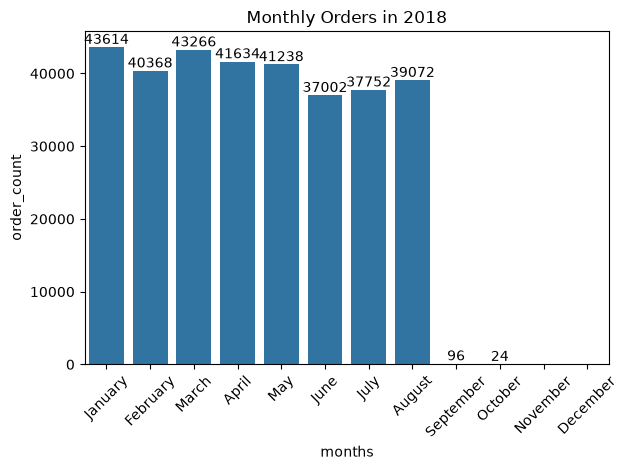

In [63]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

query = """select monthname(order_purchase_timestamp)months,count(order_id) order_count
from orders where year(order_purchase_timestamp)=2018
group by months"""

cur.execute(query)
data = cur.fetchall()

df = pd.DataFrame(data, columns=["months", "order_count"])


o = ['January', 'February', 'March', 'April','May', 'June', 'July', 'August','September', 'October', 'November', 'December']
plt.Figure(figsize=(8,13))
ax=sns.barplot(data=df,x=df["months"],y=df["order_count"],order=o)
plt.xticks(rotation=45)
ax.bar_label(ax.containers[0])
plt.title("Monthly Orders in 2018")
plt.tight_layout()
plt.show()


 Find the average number of products per order, grouped by customer city

In [90]:
query = """with count_per_order as (select orders.
order_id, orders.customer_id,count(order_items.order_id)as oc
from orders 
join order_items
on orders.order_id= order_items.order_id
group by orders.order_id,orders.customer_id)

select customers.customer_city, round(avg(count_per_order.oc),2) as average_orders
from customers
join count_per_order
on customers.customer_id =count_per_order.customer_id
group by customers.customer_city order by average_orders desc """

cur.execute(query)
data = cur.fetchall()
df=pd.DataFrame(data,columns=["Customer_city","average_products/order"])
df.head(10)


,Customer_city,average_products/order
0,padre carvalho,294.00
1,celso ramos,273.00
2,datas,252.00
3,candido godoi,252.00
4,matias olimpio,210.00
5,cidelandia,168.00
6,curralinho,168.00
7,picarra,168.00
8,morro de sao paulo,168.00
9,teixeira soares,168.00


Calculate the percentage of total revenue contributed by each product category

In [95]:
query = """select products.product_category category,round((sum(payments.payment_value)/(select sum(payment_value) from payments))*100,2) sales
from products join order_items
on products.product_id = order_items.product_id
join payments
on payments.order_id = order_items.order_id
group by category
ORDER BY sales DESC """

cur.execute(query)
data = cur.fetchall()
df=pd.DataFrame(data,columns=["Catergory","Percentage distribution "])
df.head(10)

,Catergory,Percentage distribution
0,bed table bath,192.56
1,HEALTH BEAUTY,186.35
2,computer accessories,178.25
3,Furniture Decoration,160.81
4,Watches present,160.70
5,sport leisure,156.53
6,housewares,123.09
7,automotive,95.83
8,Garden tools,94.25
9,Cool Stuff,87.67


Identify the correlation between product price and the number of times a product has been purchased

In [110]:
import numpy as np
query = """select products.product_category,
count(order_items.product_id) as total_products,
round(avg(order_items.price),2) as average_price
from products
join order_items 
on products.product_id=order_items.product_id
group by products.product_category """

cur.execute(query)
data = cur.fetchall()
df=pd.DataFrame(data,columns=["Catergory","order_count","price"])
# df.head(10)
arr=df["order_count"]
arr1=df["price"]
a=np.corrcoef([arr,arr1])
print("the correlation between price and number of times a product has been purchased",a[0][-1])


the correlation between price and number of times a product has been purchased -0.10631514167157556


 Calculate the total revenue generated by each seller, and rank them by revenue

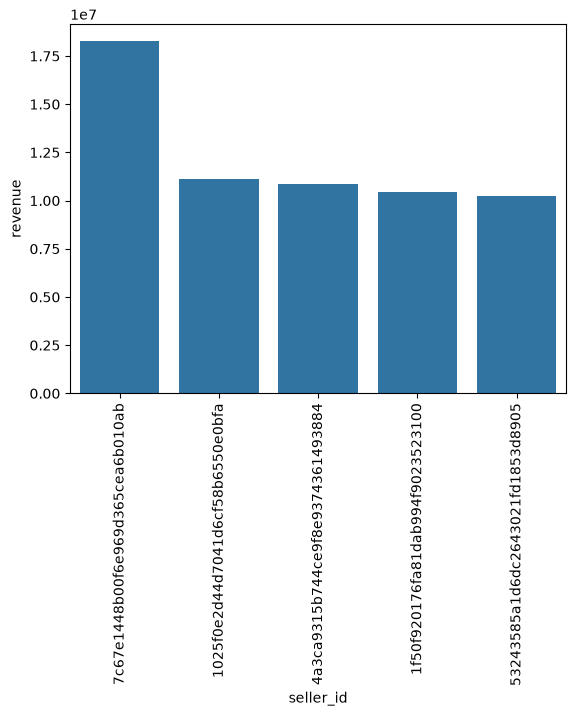

In [119]:
query = """SELECT *,
       DENSE_RANK() OVER (ORDER BY revenue DESC) AS rn
FROM (
    SELECT
        order_items.seller_id,
        SUM(payments.payment_value) AS revenue
    FROM order_items
    JOIN payments
        ON order_items.order_id = payments.order_id
    GROUP BY order_items.seller_id
) AS seller_revenue"""

cur.execute(query)
data = cur.fetchall()
data
df=pd.DataFrame(data,columns=["seller_id","revenue","rank"]).head()

sns.barplot(x="seller_id",y="revenue",data=df)
plt.xticks(rotation=90)
plt.show()

 Calculate the moving average of order values for each customer over their order history

In [ ]:

query = """
SELECT
    customer_id,
    order_purchase_timestamp,
    payment,
    AVG(payment) OVER (
        PARTITION BY customer_id
        ORDER BY order_purchase_timestamp
        ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
    ) AS mov_avg
FROM (
    SELECT
        o.customer_id,
        o.order_purchase_timestamp,
        p.payment_value AS payment
    FROM orders AS o
    JOIN payments AS p
        ON p.order_id = o.order_id
) AS a;
"""

cur.execute(query)
data = cur.fetchall()

print(data)


cur.execute(query)
data = cur.fetchall()

print(data)


In [ ]:
# mkdir fastapi_project
# cd fastapi_project
# code 

SyntaxError: invalid syntax (1417840972.py, line 1)